In [1]:
import cv2
import numpy as np
import mediapipe as mp
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, Dense, Dropout, BatchNormalization, 
    LayerNormalization, Concatenate
)
from tensorflow.keras.optimizers import Adam,SGD 
from tensorflow.keras.layers import TimeDistributed
from scipy.spatial import distance
import logging
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, List, Optional, Tuple
from datetime import datetime
from dataclasses import dataclass

In [2]:
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

In [3]:
@dataclass
class FeatureMetadata:
    """Metadata for extracted features"""
    name: str
    shape: tuple
    description: str 

In [4]:
def sample_frames(video_path: str, max_frames: int, target_size: tuple = (224, 224)) -> Optional[np.ndarray]:
    """
    Sample frames uniformly from a video file.
    
    Args:
        video_path: Path to video file
        max_frames: Number of frames to sample
        target_size: Target frame size (height, width)
        
    Returns:
        np.ndarray of shape (max_frames, height, width, 3) or None if failed
    """
    try:
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise ValueError(f"Could not open video: {video_path}")

        # Get video properties
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames == 0:
            raise ValueError(f"Video has no frames: {video_path}")
        
        #---------------------------------------

        # Calculate sampling indices
        indices = np.linspace(0, total_frames - 1, max_frames, dtype=int)
        frames = []

        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = cap.read()
            if ret:
                frame = cv2.resize(frame, target_size)
                frames.append(frame)
            else:
                logger.warning(f"Failed to read frame {idx} from {video_path}")

        cap.release()

        if len(frames) < max_frames:
            logger.warning(f"Only extracted {len(frames)} frames from {video_path}")
            last_frame = frames[-1] if frames else np.zeros(
                (target_size[0], target_size[1], 3), dtype=np.uint8
            )
            frames.extend([last_frame] * (max_frames - len(frames)))
            
        #---------------------------------------

        frames_array = np.array(frames)
        logger.info(f"Successfully sampled {len(frames)} frames from {video_path}")
        return frames_array

    except Exception as e:
        logger.error(f"Error sampling frames from {video_path}: {str(e)}")
        return None

### Base Class

In [5]:
class BaseFeatureExtractor:
    """Base class for feature extractors""" 
    
    def __init__(self, name: str):
        self.name = name
        
    def extract(self, frames: np.ndarray) -> Optional[np.ndarray]:
        raise NotImplementedError
        
    def get_feature_metadata(self) -> FeatureMetadata:
        raise NotImplementedError

## Feature extractors (Visual, Motion, Facial, Gesture, etc)

### Visual Features

In [6]:
class VisualFeatureExtractor(BaseFeatureExtractor):
    """
    Extracts visual features using ResNet50 or any other model.
    Output shape: (num_frames, 2048)
    """ 
    
    def __init__(self):
        super().__init__("visual")
        self.model = ResNet50(weights='imagenet', include_top=False, pooling='avg')
        logger.info("Initialized ResNet50 model for visual feature extraction")

    def extract(self, frames: np.ndarray) -> Optional[np.ndarray]:
        
        try:
            features = []
            for frame in frames:
                
                # Preprocess frame
                frame = preprocess_input(frame.astype(np.float32))
                frame = np.expand_dims(frame, axis=0)
                
                # Extract features
                feature = self.model.predict(frame, verbose=0)
                features.append(feature.flatten())
            
            features_array = np.array(features)
            logger.info(f"Extracted visual features with shape {features_array.shape}")
            return features_array

        except Exception as e:
            logger.error(f"Error in visual feature extraction: {str(e)}")
            return None

    def get_feature_metadata(self) -> FeatureMetadata:
        return FeatureMetadata(
            name="visual",
            shape=(2048,),
            description="ResNet50 visual features extracedd"
        )

### Motion Features

In [7]:
        
class MotionFeatureExtractor(BaseFeatureExtractor):
    """
    Extracts motion features using optical flow.
    Output shape: (num_frames, 8)
    Features: [mean_magnitude, std_magnitude, max_magnitude, mean_angle, 
              std_angle, motion_direction_x, motion_direction_y, motion_intensity]
    """
    def __init__(self): 
        
        super().__init__("motion")
        self.flow_params = dict(
            pyr_scale=0.5,
            levels=3,
            winsize=15,
            iterations=3,
            poly_n=5,
            poly_sigma=1.2,
            flags=0
        )

    def extract(self, frames: np.ndarray) -> Optional[np.ndarray]:
        
        try:
            motion_features = []
            prev_frame = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
            
            for frame in frames[1:]:
                curr_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
                
                # Calculate optical flow
                flow = cv2.calcOpticalFlowFarneback(
                    prev_frame, curr_frame, None, **self.flow_params
                )
                
                # Calculate magnitude and angle
                magnitude, angle = cv2.cartToPolar(flow[..., 0], flow[..., 1])
                
                # Extract motion statistics
                mean_mag = np.mean(magnitude)
                std_mag = np.std(magnitude)
                max_mag = np.max(magnitude)
                mean_angle = np.mean(angle)
                std_angle = np.std(angle)
                
                # Calculate motion direction
                motion_dir_x = np.mean(flow[..., 0])
                motion_dir_y = np.mean(flow[..., 1])
                
                # Calculate motion intensity
                motion_intensity = np.mean(np.sqrt(flow[..., 0]**2 + flow[..., 1]**2))
                
                features = [
                    mean_mag, std_mag, max_mag, mean_angle, std_angle,
                    motion_dir_x, motion_dir_y, motion_intensity
                ]
                motion_features.append(features)
                prev_frame = curr_frame
            
            # Handle first frame (no motion)
            motion_features.insert(0, [0] * 8)
            
            features_array = np.array(motion_features)
            logger.info(f"Extracted motion features with shape {features_array.shape}")
            return features_array

        except Exception as e:
            logger.error(f"Error in motion feature extraction: {str(e)}")
            return None

    def get_feature_metadata(self) -> FeatureMetadata:
        return FeatureMetadata(
            name="motion",
            shape=(8,),
            description="Optical flow motion features"
        )

### Facial Expression

In [8]:
class FacialFeatureExtractor(BaseFeatureExtractor):
    
    """
    Extracts facial features using MediaPipe Face Mesh.
    Output shape: (num_frames, 15)
    Features: [eye_aspect_ratio_left, eye_aspect_ratio_right, mouth_aspect_ratio,
              eye_distance, eyebrow_height, mouth_height, face_width, face_height,
              nose_tip_position_x, nose_tip_position_y, face_tilt,
              left_eye_openness, right_eye_openness, mouth_openness, smile_ratio]
    """
    
    def __init__(self):
        super().__init__("facial") 
        self.face_mesh = mp.solutions.face_mesh.FaceMesh(
            max_num_faces=1,
            min_detection_confidence=0.5,
            min_tracking_confidence=0.5
        )

    def _calculate_eye_aspect_ratio(self, eye_landmarks: np.ndarray) -> float:
        """Calculate the eye aspect ratio"""
        
        vertical_dist = (
            distance.euclidean(eye_landmarks[1], eye_landmarks[5]) +
            distance.euclidean(eye_landmarks[2], eye_landmarks[4])
        ) / 2
        horizontal_dist = distance.euclidean(eye_landmarks[0], eye_landmarks[3])
        return vertical_dist / horizontal_dist if horizontal_dist > 0 else 0

    def extract(self, frames: np.ndarray) -> Optional[np.ndarray]:
        try:
            facial_features = []
            
            for frame in frames:
                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                results = self.face_mesh.process(frame_rgb)
                
                if results.multi_face_landmarks:
                    landmarks = np.array([[lm.x, lm.y, lm.z] 
                                        for lm in results.multi_face_landmarks[0].landmark])
                    
                    # Extract facial measurements
                    left_eye = landmarks[33:38]
                    right_eye = landmarks[133:138]
                    mouth_points = landmarks[0:17]
                    
                    features = [
                        self._calculate_eye_aspect_ratio(left_eye),
                        self._calculate_eye_aspect_ratio(right_eye),
                        distance.euclidean(mouth_points[0], mouth_points[6]),  # mouth ratio
                        distance.euclidean(landmarks[33], landmarks[133]),     # eye distance
                        np.mean([landmarks[66][1], landmarks[105][1]]),       # eyebrow height
                        distance.euclidean(landmarks[0], landmarks[17]),      # mouth height
                        distance.euclidean(landmarks[234], landmarks[454]),   # face width
                        distance.euclidean(landmarks[10], landmarks[152]),    # face height
                        landmarks[4][0],                                      # nose tip x
                        landmarks[4][1],                                      # nose tip y
                        np.arctan2(landmarks[33][1] - landmarks[133][1],     # face tilt
                                 landmarks[33][0] - landmarks[133][0]),
                        np.mean([landmarks[159][2], landmarks[145][2]]),     # left eye openness
                        np.mean([landmarks[386][2], landmarks[374][2]]),     # right eye openness
                        np.mean([landmarks[13][2], landmarks[14][2]]),       # mouth openness
                        distance.euclidean(landmarks[61], landmarks[291])     # smile ratio
                    ]
                else:
                    features = [0] * 15  # No face detected
                    
                facial_features.append(features)
            
            features_array = np.array(facial_features)
            logger.info(f"Extracted facial features with shape {features_array.shape}")
            return features_array

        except Exception as e:
            logger.error(f"Error in facial feature extraction: {str(e)}")
            return None

    def get_feature_metadata(self) -> FeatureMetadata:
        return FeatureMetadata(
            name="facial",
            shape=(15,),
            description="MediaPipe Face Mesh features"
        )

### Gesture Feature Extraction

In [9]:
class GestureFeatureExtractor(BaseFeatureExtractor):
    """
    Extracts gesture features using MediaPipe Hands.
    Output shape: (num_frames, 42) - 21 landmarks x 2 coordinates (x, y)
    """
    def __init__(self):
        super().__init__("gesture")
        self.hands = mp.solutions.hands.Hands(
            static_image_mode=False,
            max_num_hands=4,
            min_detection_confidence=0.5,
            min_tracking_confidence=0.5
        )
        
    def extract(self, frames: np.ndarray) -> Optional[np.ndarray]:
        try:
            gesture_features = []
            
            for frame in frames:
                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                results = self.hands.process(frame_rgb)
                
                frame_features = []
                if results.multi_hand_landmarks:
                    # Get the first hand's landmarks
                    hand_landmarks = results.multi_hand_landmarks[0]
                    
                    # Extract x, y coordinates for each landmark
                    for landmark in hand_landmarks.landmark:
                        frame_features.extend([landmark.x, landmark.y])
                        
                    # Calculate additional gesture metrics
                    # Distance between thumb tip and index finger tip (pinch)
                    thumb_tip = np.array([hand_landmarks.landmark[4].x, hand_landmarks.landmark[4].y])
                    index_tip = np.array([hand_landmarks.landmark[8].x, hand_landmarks.landmark[8].y])
                    pinch_distance = np.linalg.norm(thumb_tip - index_tip)
                    
                    # Overall hand spread (distance between thumb tip and pinky tip)
                    pinky_tip = np.array([hand_landmarks.landmark[20].x, hand_landmarks.landmark[20].y])
                    hand_spread = np.linalg.norm(thumb_tip - pinky_tip)
                    
                    # Hand orientation (angle between middle finger and palm)
                    wrist = np.array([hand_landmarks.landmark[0].x, hand_landmarks.landmark[0].y])
                    middle_tip = np.array([hand_landmarks.landmark[12].x, hand_landmarks.landmark[12].y])
                    orientation = np.arctan2(middle_tip[1] - wrist[1], middle_tip[0] - wrist[0])
                    
                    frame_features.extend([pinch_distance, hand_spread, orientation])
                else:
                    # If no hand detected, fill with zeros
                    frame_features = [0.0] * 45  # 21 landmarks * 2 + 3 metrics
                
                gesture_features.append(frame_features)
            
            features_array = np.array(gesture_features)
            logger.info(f"Extracted gesture features with shape {features_array.shape}")
            return features_array

        except Exception as e:
            logger.error(f"Error in gesture feature extraction: {str(e)}")
            return None

    def get_feature_metadata(self) -> FeatureMetadata:
        return FeatureMetadata(
            name="gesture",
            shape=(45,),
            description="MediaPipe Hands landmarks and gesture metrics"
        )

In [ ]:
class AudioFeatures():
    def__init__(self):
        self.audio_features = []

## Individual model class

In [10]:
class ModalitySpecificLSTM:
    def __init__(self, input_shape: tuple, modality_name: str):
        self.input_shape = input_shape
        self.modality_name = modality_name
        self.model = self._create_model()

    def _create_model(self) -> Model:
        inputs = Input(shape=self.input_shape)
        
        # First LSTM layer
        x = LSTM(512, return_sequences=True)(inputs)
        x = BatchNormalization()(x)
        x = Dropout(0.2)(x)
        
        # Second LSTM layer with return_sequences=False to get rid of temporal dimension
        x = LSTM(256, return_sequences=False)(x)
        x = BatchNormalization()(x)
        x = Dropout(0.2)(x)
        
        # Dense layers without TimeDistributed
        x = Dense(128, activation='relu')(x)
        x = BatchNormalization()(x)
        outputs = Dense(32, activation='relu')(x)
        
        model = Model(inputs=inputs, outputs=outputs, name=f"{self.modality_name}_lstm")
        model.compile(optimizer=Adam(learning_rate=0.002), loss='mse')
        
        return model

    def process_sequence(self, features: np.ndarray) -> np.ndarray:
        try:
            # Log input shape
            logger.info(f"Input features shape for {self.modality_name}: {features.shape}")
            
            # Process features
            processed_features = self.model.predict(features, verbose=0)
            
            # Add sequence dimension for FusionLSTM
            processed_features = np.expand_dims(processed_features, axis=1)
            
            # Log output shape
            logger.info(f"Processed {self.modality_name} features shape: {processed_features.shape}")
        
            return processed_features
            
        except Exception as e:
            logger.error(f"Error processing {self.modality_name} features: {str(e)}")
            return None 

# Fusion Model

In [11]:
class FusionLSTM:
    def __init__(self, input_shapes: Dict[str, tuple], num_classes: int):
        self.input_shapes = input_shapes
        self.num_classes = num_classes
        self.model = self._create_fusion_model()

    def _create_fusion_model(self) -> Model:
        # Create input layers for each modality
        inputs = {
            name: Input(shape=(1, 32), name=f"{name}_input")
            for name in self.input_shapes.keys()
        }
        
        # Concatenate all inputs along feature dimension
        concatenated = Concatenate(axis=-1)(list(inputs.values()))
        
        # Process combined features
        x = LSTM(512, return_sequences=True)(concatenated)
        x = BatchNormalization()(x)
        x = Dropout(0.2)(x)
        
        x = LSTM(256)(x)
        x = BatchNormalization()(x)
        x = Dropout(0.2)(x)
        
        x = Dense(128, activation='relu')(x)
        x = BatchNormalization()(x)
        x = Dropout(0.1)(x)

        x = Dense(64, activation='relu')(x)
        x = BatchNormalization()(x)
        
        outputs = Dense(self.num_classes, activation='softmax')(x)
        
        model = Model(inputs=inputs, outputs=outputs)
        model.compile(
            optimizer=Adam(learning_rate=0.002),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
        
        return model

    def train(self, features: Dict[str, np.ndarray], labels: np.ndarray, **kwargs) -> tf.keras.callbacks.History:
        try:
            # Log shapes before training
            for name, feature in features.items():
                logger.info(f"Feature '{name}' shape before training: {feature.shape}")
                
                # Ensure correct shape (batch_size, 1, 16)
                if len(feature.shape) > 3:
                    features[name] = feature.squeeze(axis=2)
                logger.info(f"Feature '{name}' shape after reshaping: {features[name].shape}")
            
            history = self.model.fit(
                x=features,
                y=labels,
                **kwargs
            )
            return history
        except Exception as e:
            logger.error(f"Error training fusion model: {str(e)}")
            return None

    def predict(self, features: Dict[str, np.ndarray]) -> np.ndarray:
        """
        Generate predictions for the given features.
        
        Args:
            features: Dictionary of features for each modality
            
        Returns:
            Numpy array of predictions
        """
        try:
            # Ensure correct shape for prediction
            reshaped_features = {}
            for name, feature in features.items():
                if len(feature.shape) > 3:
                    reshaped_features[name] = feature.squeeze(axis=2)
                else:
                    reshaped_features[name] = feature
                logger.info(f"Feature '{name}' shape for prediction: {reshaped_features[name].shape}")
            
            # Generate predictions
            predictions = self.model.predict(reshaped_features, verbose=0)
            logger.info(f"Generated predictions with shape: {predictions.shape}")
            
            return predictions
            
        except Exception as e:
            logger.error(f"Error generating predictions: {str(e)}")
            return None

    def evaluate(self, features: Dict[str, np.ndarray], labels: np.ndarray) -> Tuple[float, float]:
        """
        Evaluate the model on the given features and labels.
        
        Args:
            features: Dictionary of features for each modality
            labels: Ground truth labels
            
        Returns:
            Tuple of (loss, accuracy)
        """
        try:
            # Ensure correct shape for evaluation
            reshaped_features = {}
            for name, feature in features.items():
                if len(feature.shape) > 3:
                    reshaped_features[name] = feature.squeeze(axis=2)
                else:
                    reshaped_features[name] = feature
                    
            # Evaluate model
            results = self.model.evaluate(reshaped_features, labels, verbose=0)
            logger.info(f"Evaluation results - Loss: {results[0]:.4f}, Accuracy: {results[1]:.4f}")
            
            return results
            
        except Exception as e:
            logger.error(f"Error in model evaluation: {str(e)}")
            return None

### Classification Pipeline

In [12]:
class VideoClassificationPipeline:
    """
    End-to-end pipeline for multimodal "HowFunny" video classification.
    """
    def __init__(
        self,
        max_frames: int = 10,
        target_size: Tuple[int, int] = (224, 224),
        batch_size: int = 32,
        epochs: int = 100
    ):
        self.max_frames = max_frames
        self.target_size = target_size
        self.batch_size = batch_size
        self.epochs = epochs
        
        # Initialize feature extractors
        self.feature_extractors = {
            'visual': VisualFeatureExtractor(),
            'motion': MotionFeatureExtractor(),
            'facial': FacialFeatureExtractor(),
            'gesture': GestureFeatureExtractor(),
            'audio': AudioFeatureExtractor()
        }
        
        # Initialize modality-specific LSTMs
        self.modality_lstms = {}
        self.fusion_model = None
        self.label_encoder = LabelEncoder()
        
        logger.info("Initialized VideoClassificationPipeline")
        
    def process_video(self, video_path: str) -> Optional[Dict[str, np.ndarray]]:
        """
        Process a single video through all feature extractors.
        """
        try:
            # Sample frames
            frames = sample_frames(video_path, self.max_frames, self.target_size)
            if frames is None:
                return None
                
            # Extract features using all extractors
            features = {}
            for name, extractor in self.feature_extractors.items():
                features[name] = extractor.extract(frames)
                if features[name] is None:
                    logger.error(f"Failed to extract {name} features from {video_path}")
                    return None
                    
            return features
            
        except Exception as e:
            logger.error(f"Error processing video {video_path}: {str(e)}")
            return None
            
    def prepare_dataset(
        self,
        video_dir: str,
        metadata_path: str
    ) -> Tuple[Dict[str, np.ndarray], np.ndarray]:
        """
        Prepare dataset by processing all videos and their labels.
        """
        try:
            # Try different encodings and engines for reading the metadata
            for encoding in ['utf-8', 'latin1', 'iso-8859-1', 'cp1252']:
                try:
                    # Try using different engines
                    for engine in ['python']:
                        try:
                            metadata = pd.read_excel(
                                metadata_path,
                                encoding=encoding,
                                engine=engine,
                                on_bad_lines='skip'  # Skip problematic lines
                            )
                            logger.info(f"Successfully loaded metadata with encoding {encoding} and engine {engine}")
                            break
                        except Exception as e:
                            continue
                    break
                except Exception as e:
                    continue
            
            # If Excel file, try reading with pd.read_excel
            if metadata_path.endswith(('.xlsx', '.xls')):
                try:
                    metadata = pd.read_excel(metadata_path)
                    logger.info("Successfully loaded Excel metadata file")
                except Exception as e:
                    logger.error(f"Error reading Excel file: {str(e)}")
                    return None, None
    
            if metadata is None or len(metadata) == 0:
                logger.error("Failed to load metadata file with any method")
                return None, None
            
            
            
            # Data cleaning and preprocessing
            metadata['VideoID'] = metadata['VideoID'].astype(str).str.strip()
            metadata['HowFunny'] = metadata['HowFunny'].astype(str).str.strip()
            
            # Remove missing values and combine categories
            metadata = metadata.dropna(subset=['VideoID', 'HowFunny'])
            
            def combine_categories(x):
                x = str(x).strip()
                if x in ['Funny', 'Very funny', 'Extremely funny']:
                    return 'Very Funny'
                elif x == 'Slightly funny':
                    return 'Slightly Funny'
                elif x == 'Not funny':
                    return 'Not Funny'
                return None

            metadata['HowFunny_Combined'] = metadata['HowFunny'].apply(combine_categories)
            metadata = metadata.dropna(subset=['HowFunny_Combined'])
            
            
    
            # Print metadata information for debugging
            logger.info(f"Metadata columns: {metadata.columns.tolist()}")
            logger.info(f"First few rows of metadata:\n{metadata.head()}")
            
            # Process all videos
            all_features = {name: [] for name in self.feature_extractors.keys()}
            valid_labels = []
            
            # Get the correct column names
            video_id_col = next((col for col in metadata.columns if 'videoid' in col.lower()), None)
            label = next((col for col in metadata.columns if 'howfunny_combined' in col.lower()), None)
            
            if not video_id_col or not label:
                logger.error(f"Required columns not found. Available columns: {metadata.columns.tolist()}")
                return None, None
                
            logger.info(f"Using columns: video_id='{video_id_col}', label='{label}'")
            
            for idx, row in metadata.iterrows():
                try:
                    # Get video path
                    video_filename = str(row[video_id_col])
                    
                    # Handle different video extensions
                    for ext in ['.mp4', '.avi', '.mov', '.mkv']:
                        video_path = os.path.join(video_dir, video_filename)
                        if os.path.exists(video_path):
                            break
                    else:
                        logger.warning(f"Video file not found for ID {video_filename}")
                        continue
                    
                    # Process video
                    features = self.process_video(video_path)
                    if features is not None:
                        for name, feature in features.items():
                            all_features[name].append(feature)
                        valid_labels.append(row[label])
                        
                except Exception as e:
                    logger.error(f"Error processing video at index {idx}: {str(e)}")
                    continue
                    
            if not valid_labels:
                logger.error("No valid videos processed")
                return None, None
                
            # Converting to numpy arrays
            for name in all_features:
                all_features[name] = np.array(all_features[name])
            
            # Encoding labels
            encoded_labels = self.label_encoder.fit_transform(valid_labels)
            
            logger.info(f"Successfully processed {len(valid_labels)} videos")
            return all_features, encoded_labels
            
        except Exception as e:
            logger.error(f"Error preparing dataset: {str(e)}")
            return None, None
            
    def train(
        self,
        video_dir: str,
        metadata_path: str,
        validation_split: float = 0.2
    ) -> Optional[tf.keras.callbacks.History]:
        """
        Train the complete pipeline with detailed error logging.
        """
        try:
            logger.info("Starting training pipeline...")
            logger.info(f"Processing videos from: {video_dir}")
            logger.info(f"Using metadata from: {metadata_path}")
    
            # Step 1: Prepare dataset
            logger.info("Step 1: Preparing dataset...")
            features, labels = self.prepare_dataset(video_dir, metadata_path)
            
            if features is None or labels is None:
                logger.error("Dataset preparation failed")
                return None
                
            logger.info(f"Dataset prepared successfully. Features shapes:")
            for name, feature_array in features.items():
                logger.info(f"- {name}: {feature_array.shape}")
            logger.info(f"Number of labels: {len(labels)}")
            logger.info(f"Unique labels: {np.unique(labels)}")
    
            # Step 2: Split data
            logger.info("\nStep 2: Splitting data...")
            try:
                train_features = {}
                test_features = {}
                
                train_idx, test_idx = train_test_split(
                    np.arange(len(labels)),
                    test_size=validation_split,
                    stratify=labels,
                    random_state=42
                )
                
                for name, feature_array in features.items():
                    train_features[name] = feature_array[train_idx]
                    test_features[name] = feature_array[test_idx]
                    logger.info(f"Split {name} features - Train: {train_features[name].shape}, Test: {test_features[name].shape}")
                
                y_train, y_test = labels[train_idx], labels[test_idx]
                logger.info(f"Split labels - Train: {y_train.shape}, Test: {y_test.shape}")
                
            except Exception as e:
                logger.error(f"Error during data splitting: {str(e)}")
                return None
    
            # Step 3: Initialize and train modality-specific LSTMs
            logger.info("\nStep 3: Training modality-specific LSTMs...")
            processed_train_features = {}
            processed_test_features = {}
            
            for name, feature_array in train_features.items():
                try:
                    logger.info(f"\nProcessing {name} features...")
                    
                    # Initialize LSTM
                    self.modality_lstms[name] = ModalitySpecificLSTM(
                        input_shape=feature_array.shape[1:],
                        modality_name=name
                    )
                    
                    # Process features
                    logger.info(f"Processing training features for {name}...")
                    processed_train = self.modality_lstms[name].process_sequence(feature_array)
                    
                    logger.info(f"Processing testing features for {name}...")
                    processed_test = self.modality_lstms[name].process_sequence(test_features[name])
                    
                    if processed_train is None or processed_test is None:
                        logger.error(f"Failed to process {name} features")
                        return None
                        
                    processed_train_features[name] = processed_train
                    processed_test_features[name] = processed_test
                    
                    logger.info(f"Successfully processed {name} features")
                    logger.info(f"- Train shape: {processed_train.shape}")
                    logger.info(f"- Test shape: {processed_test.shape}")
                    
                except Exception as e:
                    logger.error(f"Error processing {name} features: {str(e)}")
                    return None
    
            # Step 4: Initialize and train fusion model
            logger.info("\nStep 4: Training fusion model...")
            try:
                num_classes = len(np.unique(labels))
                logger.info(f"Number of classes: {num_classes}")
                
                input_shapes = {name: (16,) for name in self.feature_extractors.keys()}
                logger.info(f"Input shapes for fusion model: {input_shapes}")
                
                self.fusion_model = FusionLSTM(input_shapes, num_classes)
                
                # Setup callbacks
                callbacks = [
                    tf.keras.callbacks.EarlyStopping(
                        monitor='val_accuracy',
                        patience=10,
                        restore_best_weights=True
                    ),
                    tf.keras.callbacks.ModelCheckpoint(
                        filepath=f'Multi_modal_experiements/models/fusion_model_{datetime.now().strftime("%Y%m%d_%H%M%S")}.keras',
                        monitor='val_accuracy',
                        save_best_only=True
                    ),
                    tf.keras.callbacks.TensorBoard(
                        log_dir=f'Multi_modal_experiements/logs/fusion_model_{datetime.now().strftime("%Y%m%d_%H%M%S")}',
                        histogram_freq=1
                    )
                ]
                
                # Train fusion model
                logger.info("Starting fusion model training...")
                history = self.fusion_model.train(
                    features=processed_train_features,
                    labels=y_train,
                    validation_data=(processed_test_features, y_test),
                    epochs=self.epochs,
                    batch_size=self.batch_size,
                    callbacks=callbacks
                )
                
                if history is not None:
                    logger.info("Fusion model training completed successfully")
                    self.evaluate(processed_test_features, y_test)
                    return history
                else:
                    logger.error("Fusion model training failed")
                    return None
                    
            except Exception as e:
                logger.error(f"Error in fusion model training: {str(e)}")
                return None
                
        except Exception as e:
            logger.error(f"Error in training pipeline: {str(e)}")
            return None
            
    def evaluate(
        self,
        test_features: Dict[str, np.ndarray],
        test_labels: np.ndarray
    ) -> None:
        """
        Evaluate the model and save results.
        """
        try:
            predictions = self.fusion_model.predict(test_features)
            pred_classes = np.argmax(predictions, axis=1)
            
            # Generate classification report
            report = classification_report(
                test_labels,
                pred_classes,
                target_names=self.label_encoder.classes_,
                output_dict=True
            )
            
            # Save classification report
            pd.DataFrame(report).transpose().to_csv(
                f'Multi_modal_experiements/results/classification_report_{datetime.now().strftime("%Y%m%d_%H%M%S")}.csv'
            )
            
            # Plot and save confusion matrix
            plt.figure(figsize=(10, 8))
            sns.heatmap(
                confusion_matrix(test_labels, pred_classes),
                annot=True,
                fmt='d',
                xticklabels=self.label_encoder.classes_,
                yticklabels=self.label_encoder.classes_
            )
            plt.title('Confusion Matrix')
            plt.tight_layout()
            plt.savefig(f'results/confusion_matrix_{datetime.now().strftime("%Y%m%d_%H%M%S")}.png')
            plt.close()
            
            logger.info("Evaluation completed and results saved")
            
        except Exception as e:
            logger.error(f"Error in evaluation: {str(e)}")

# Main File

2025-01-20 23:45:40,089 - __main__ - INFO - Video directory: /Users/jeremiah/video-p-reaction-joketype-modular/data/videos
2025-01-20 23:45:40,089 - __main__ - INFO - Metadata path: /Users/jeremiah/phd_thesis/data/main_data/excel2_modified_filtered_sorted_by_Total Seconds.xlsx
2025-01-20 23:45:40,095 - __main__ - INFO - Found 1425 video files
2025-01-20 23:45:40,587 - __main__ - INFO - Initialized ResNet50 model for visual feature extraction
2025-01-20 23:45:40,663 - __main__ - INFO - Initialized VideoClassificationPipeline
I0000 00:00:1737416740.658133  561316 gl_context.cc:357] GL version: 2.1 (2.1 Metal - 88.1), renderer: Apple M3 Pro
I0000 00:00:1737416740.662750  561316 gl_context.cc:357] GL version: 2.1 (2.1 Metal - 88.1), renderer: Apple M3 Pro
2025-01-20 23:45:40,663 - __main__ - INFO - Starting training pipeline...
2025-01-20 23:45:40,663 - __main__ - INFO - Processing videos from: /Users/jeremiah/video-p-reaction-joketype-modular/data/videos
2025-01-20 23:45:40,664 - __main__

2025-01-21 00:01:12,566 - tensorflow - WARNING - 5 out of the last 13505 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x391ae4ae0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2025-01-21 00:01:12,569 - __main__ - INFO - Processed motion features shape: (49, 1, 32)
2025-01-21 00:01:12,569 - __main__ - INFO - Processing testing features for motion...
2025-01-21 00:01:12,569 - __main__ - INFO - Input features shape for mot

2025-01-21 00:01:12,809 - tensorflow - WARNING - 6 out of the last 13507 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x3918a68e0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2025-01-21 00:01:12,926 - __main__ - INFO - Processed facial features shape: (49, 1, 32)
2025-01-21 00:01:12,926 - __main__ - INFO - Processing testing features for facial...
2025-01-21 00:01:12,926 - __main__ - INFO - Input features shape for fac

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 433ms/step - accuracy: 0.3731 - loss: 1.6154 - val_accuracy: 0.3846 - val_loss: 1.0939
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.7398 - loss: 0.8016 - val_accuracy: 0.3846 - val_loss: 1.0914
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.7702 - loss: 0.7197 - val_accuracy: 0.3846 - val_loss: 1.0885
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.8423 - loss: 0.5207 - val_accuracy: 0.3846 - val_loss: 1.0862
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9039 - loss: 0.3522 - val_accuracy: 0.3846 - val_loss: 1.0836
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.9760 - loss: 0.2639 - val_accuracy: 0.3846 - val_loss: 1.0812
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.9760 - loss: 0.2234 - val_accuracy: 0.3077 - val_loss: 1.0793
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 1.0000 - loss: 0.1620 - val_accuracy: 0.3846 - v

2025-01-21 00:01:17,193 - __main__ - INFO - Fusion model training completed successfully
2025-01-21 00:01:17,193 - __main__ - INFO - Feature 'visual' shape for prediction: (13, 1, 32)
2025-01-21 00:01:17,193 - __main__ - INFO - Feature 'motion' shape for prediction: (13, 1, 32)
2025-01-21 00:01:17,194 - __main__ - INFO - Feature 'facial' shape for prediction: (13, 1, 32)
2025-01-21 00:01:17,194 - __main__ - INFO - Feature 'gesture' shape for prediction: (13, 1, 32)
2025-01-21 00:01:17,326 - __main__ - INFO - Generated predictions with shape: (13, 3)
/opt/anaconda3/envs/videop/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/envs/videop/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetri

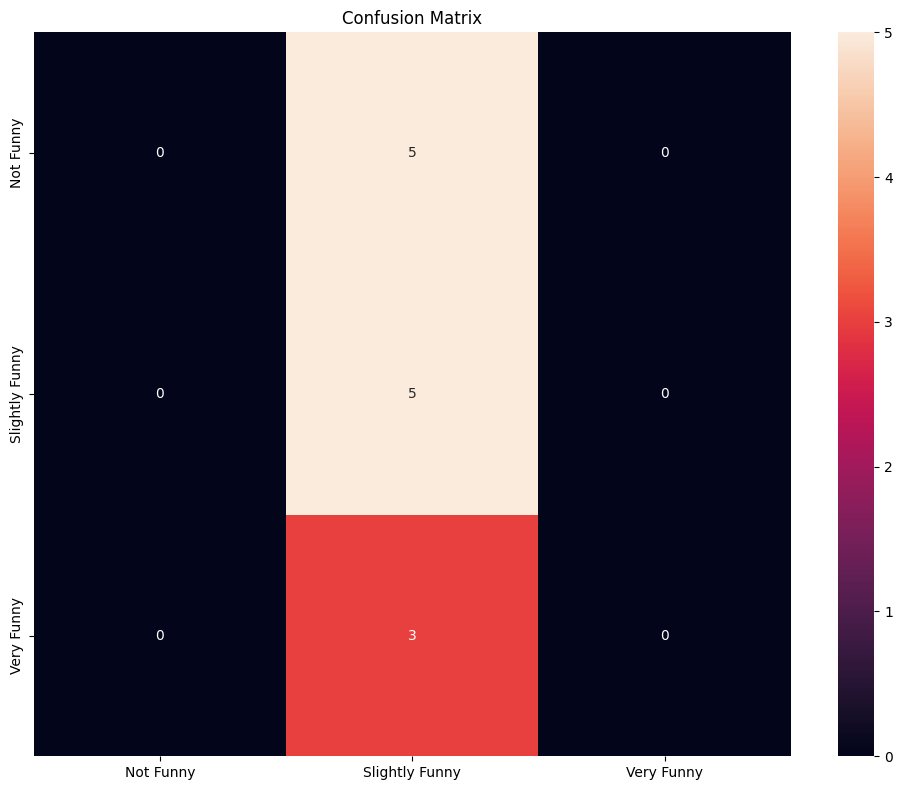

In [13]:
def main():
    """
    Main execution function with detailed error checking.
    """
    try:
        # Set random seeds for reproducibility
        tf.random.set_seed(5454542)
        np.random.seed(4454542)
        
        # Create directories for outputs
        os.makedirs('Multi_modal_experiements/models', exist_ok=True)
        os.makedirs('Multi_modal_experiements/results', exist_ok=True)
        os.makedirs('Multi_modal_experiements/logs', exist_ok=True)
        
        # Define paths
        video_dir = '/Users/jeremiah/video-p-reaction-joketype-modular/data/videos'  
        metadata_path = '/Users/jeremiah/phd_thesis/data/main_data/excel2_modified_filtered_sorted_by_Total Seconds.xlsx' 
        
        # Verify paths exist
        if not os.path.exists(video_dir):
            raise ValueError(f"Video directory not found: {video_dir}")
        if not os.path.exists(metadata_path):
            raise ValueError(f"Metadata file not found: {metadata_path}")
            
        logger.info(f"Video directory: {video_dir}")
        logger.info(f"Metadata path: {metadata_path}")
        
        # Check video directory contents
        video_files = [f for f in os.listdir(video_dir) if f.endswith(('.mp4', '.avi', '.mov', '.mkv'))]
        logger.info(f"Found {len(video_files)} video files")
        if len(video_files) == 0:
            raise ValueError("No video files found in directory")
        
        # Initialize pipeline
        pipeline = VideoClassificationPipeline(
            max_frames=10,
            target_size=(224, 224),
            batch_size=32,
            epochs=100
        )
        
        # Train pipeline
        history = pipeline.train(video_dir, metadata_path)
        
        if history is not None:
            logger.info("Training completed successfully")
            
            # Plot training history
            plt.figure(figsize=(12, 4))
            
            plt.subplot(1, 2, 1)
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.title('Model Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.legend()
            
            plt.subplot(1, 2, 2)
            plt.plot(history.history['accuracy'], label='Training Accuracy')
            plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
            plt.title('Model Accuracy')
            plt.xlabel('Epoch')
            plt.ylabel('Accuracy')
            plt.legend()
            
            plt.tight_layout()
            plt.savefig(f'Multi_modal_experiements/results/training_history_{datetime.now().strftime("%Y%m%d_%H%M%S")}.png')
            plt.close() 
        else:
            logger.error("Training failed")
            
    except Exception as e:
        logger.error(f"Error in main execution: {str(e)}")
        raise  # Re-raise the exception to see the full traceback

if __name__ == "__main__":
    main()

**Frame Sampling**

- Uniform sampling ensures consistent temporal coverage
- Resizing maintains computational efficiency
- Frame normalization improves model stability

**Feature Types**

- Visual (ResNet): Captures spatial patterns and scene content
- Motion (Optical Flow): Captures temporal dynamics
- Facial: Captures emotional expressions
- Interaction: Captures interpersonal dynamics
- Gesture: Captures body language

**Model Architecture**

- Separate sequence models: Allow each feature type to learn its own temporal patterns
- Intermediate fusion: Combines high-level representations from each modality
- Final classification: Makes predictions based on fused features